# Select-DPC: original implementation, final-target benchmark

Seeds **10001–10500 (500 seeds)**, **300 control steps**, authors’ original IID data, **200 raw columns**, five refinements per step, and **Clarabel**. No Atlas controller is run, and no graph or waypoint reference is added.

**500-seed evaluation:** controller settings are unchanged from the 211–310 development run. A separate output directory preserves those previous results. Completed evaluation seeds are reused automatically; an interrupted seed restarts from its beginning. Run this notebook and contextual DPC sequentially for comparable timings.

The upstream checkout is unchanged at commit `8afa3b36ca47570400b0b8ff82328ab25ee3fdee`. The adapter loads the authors’ `setup_DeePC`, `fix_dataset`, and `DefaultReacherSetpoint` definitions directly from their notebook. Only solver dispatch, experiment orchestration, and logging are external.

**Run instructions:** inspect cells below with `RUN_EXPERIMENT = False`. When ready, change it to `True` and run the **Resume experiment** cell. Keep the seed range and configuration unchanged to reuse existing results. You may interrupt the cell; only the unfinished seed needs to restart.

**300-step paper evaluation:** uses a new output directory; the existing 100-seed development results remain separate. Previous 320-step held-out traces must not be silently reused or relabeled. Success windows end at step 300, costs cover steps 1–300, and trimmed timing covers steps 6–300.


In [ ]:
from pathlib import Path
import json, os, sys, subprocess, signal, hashlib, fcntl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/atlas_deepc/benchmarks/select_dpc_upstream.py").is_file())
RESULT_DIR = ROOT / "experiments/reacher/select_dpc_upstream_final_clarabel_10001_10500_t300_v1"
RUNNER = ROOT / "src/atlas_deepc/benchmarks/select_dpc_upstream.py"
# Use the existing isolated environment: includes the upstream torch dependency.
PYTHON = ROOT / "tmp/select_dpc_upstream_env/bin/python"
SEED_START, SEED_STOP, T_sim = 10001, 10500, 300
STEPS = T_sim
# Each invocation stops after this many NEW complete seeds.
BATCH_SIZE = 100  # ~3 h 20 min at 1.6 seconds per step; try 10 for ~1 h 20 min.
BLOCK_NUMBER = None  # None: next unfinished seeds; 1, 2, ...: a specific numbered block.
RUN_EXPERIMENT = True  # Explicit opt-in; restoring the notebook does not start a run.

def batch_bounds():
    assert isinstance(BATCH_SIZE, int) and BATCH_SIZE > 0, 'BATCH_SIZE must be a positive integer'
    if BLOCK_NUMBER is None:
        return SEED_START, SEED_STOP
    count = (SEED_STOP - SEED_START + BATCH_SIZE) // BATCH_SIZE
    assert isinstance(BLOCK_NUMBER, int) and 1 <= BLOCK_NUMBER <= count, f'Choose block 1–{count}'
    start = SEED_START + (BLOCK_NUMBER - 1) * BATCH_SIZE
    return start, min(start + BATCH_SIZE - 1, SEED_STOP)

def worker_running():
    if not (RESULT_DIR / "run.lock").exists():
        return False
    with (RESULT_DIR / "run.lock").open("r") as lock:
        try:
            fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError:
            return True
        else:
            fcntl.flock(lock, fcntl.LOCK_UN)
            return False

print(f"Requested seeds: {SEED_START}–{SEED_STOP} ({SEED_STOP-SEED_START+1} seeds); {STEPS} control steps")
print("Results:", RESULT_DIR)
print("Background worker active:", worker_running())
print("Resume enabled:", RUN_EXPERIMENT)

block_start, block_stop = batch_bounds()
missing = [s for s in range(block_start, block_stop + 1)
           if not (RESULT_DIR / f'seed{s}_control_results.npz').exists()]
planned = missing[:BATCH_SIZE]
print('Batch mode:', 'next unfinished seeds' if BLOCK_NUMBER is None else f'block {BLOCK_NUMBER}')
print('Seeds planned:', planned)
print(f'Estimated compute time: {len(planned) * STEPS * 1.6 / 3600:.2f} hours, plus overhead')


Requested seeds: 10001–10500 (500 seeds); 300 control steps
Results: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/select_dpc_upstream_final_clarabel_10001_10500_t300_v1
Background worker active: False
Resume enabled: True
Batch mode: next unfinished seeds
Seeds planned: [10001, 10002, 10003, 10004, 10005, 10006, 10007, 10008, 10009, 10010, 10011, 10012, 10013, 10014, 10015, 10016, 10017, 10018, 10019, 10020, 10021, 10022, 10023, 10024, 10025, 10026, 10027, 10028, 10029, 10030, 10031, 10032, 10033, 10034, 10035, 10036, 10037, 10038, 10039, 10040, 10041, 10042, 10043, 10044, 10045, 10046, 10047, 10048, 10049, 10050, 10051, 10052, 10053, 10054, 10055, 10056, 10057, 10058, 10059, 10060, 10061, 10062, 10063, 10064, 10065, 10066, 10067, 10068, 10069, 10070, 10071, 10072, 10073, 10074, 10075, 10076, 10077, 10078, 10079, 10080, 10081, 10082, 10083, 10084, 10085, 10086, 10087, 10088, 10089, 10090, 10091, 10092, 10093, 10094, 10095, 10096, 10097, 10098, 10099, 10100, 10101, 101

## What is preserved, and what differs from Atlas

| Setting | This Select-DPC run |
|---|---|
| Offline data | Authors’ released `dataset_iid`; exploration approximately ±0.1, **not** the Atlas dataset with ±1 exploration |
| Environment / initialization | Original Reacher-v4; repeated-state controller initialization; no physical warmup |
| Outputs / horizon | Original eight outputs; past 2, future 15 |
| Selection | Original L1 trajectory selector; 200 raw columns; five refinement solves |
| QP | Original objective, projection regularization, L1 penalties, affine sum constraint, and fallback behavior |
| Reference | Original `DefaultReacherSetpoint`: each seed’s final Cartesian target; no waypoints |
| Constraints | Original input ±0.5 and predicted fingertip height ≤0.1 m |
| Solver adapter | Clarabel; `max_iter=6000`, `warm_start=False`, default tolerances, one solver thread, internal KKT stabilization `static_regularization_constant=1e-6` |
| Timing | Entire control call, all five refinements and QP construction/pseudoinverse; excludes environment stepping and file writes; includes instrumentation overhead |

Clarabel’s default internal stabilization failed the initial pilot. The documented solver setting changes numerical factorization, **not** the controller objective or its regularization weights. Solver statuses and constraint residuals are saved.

**Success matches the Atlas baseline:** both the last-30 and last-100 windows must have mean fingertip error <10 mm and maximum error <20 mm. Partial results describe completed seeds only.

**Cost warning:** saved closed-loop stage costs use Select-DPC’s own Q/R, evaluated on post-action outputs like the baseline. Do not directly rank these against Atlas costs with different Q/R. Raw traces and unweighted XY/input metrics are retained for common rescoring. Targets above the original height constraint are flagged.


In [8]:
manifest_path = RESULT_DIR / "manifest.json"
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text())
    expected = manifest["runner_sha256"]
    actual = hashlib.sha256(RUNNER.read_bytes()).hexdigest()
    print("Runner matches saved protocol:", actual == expected)
    print("Upstream commit:", manifest["upstream_commit"])
    print("Clarabel settings:", manifest["clarabel_options"])
    print("Interpreter available:", PYTHON.is_file())
    print("Requested seeds:", manifest["seed_start"], "through", manifest["seed_stop"])
else:
    print("No saved manifest yet.")
progress_path = RESULT_DIR / "progress.json"
if progress_path.exists():
    progress = json.loads(progress_path.read_text())
    print("Latest checkpoint:", progress)
print("Worker currently active:", worker_running())


No saved manifest yet.
Worker currently active: False


## Run one batch / resume

Keep the full panel fixed at **10001–10500**, with **T_sim=300**. Change only **BATCH_SIZE** and optionally **BLOCK_NUMBER**.

- Default: `BATCH_SIZE=25`, `BLOCK_NUMBER=None`. Each invocation runs the next 25 unfinished seeds and exits. Run the same cell later to continue.
- Numbered blocks: `BLOCK_NUMBER=1` runs 10001–10025, `2` runs 10026–10050, and so on (with batch size 25). Rerunning a block skips its completed seeds.
- Smaller sessions: `BATCH_SIZE=10` is approximately 1 h 20 min at 1.6 seconds/step; 25 is 3 h 20 min; 50 is 6 h 40 min. Total 500-seed compute estimate: **66 h 40 min**, excluding overhead and time paused.
- Set `RUN_EXPERIMENT=True` when ready. This cell launches only one batch, not subsequent batches automatically.
- Completed seeds are saved individually. Interrupting preserves them; the unfinished seed restarts from step 1. Wait for the child to stop before closing the notebook or transporting/sleeping the laptop.
- All blocks share one output directory and one fixed protocol manifest. Statistics cover **all completed seeds across all blocks**; `complete=true` is reserved for the entire 500-seed panel. `batch_complete` means this session finished, not all 500 seeds.
- Run after contextual DPC finishes for comparable timing measurements. This notebook does not interrupt contextual DPC.

Keep the notebook open while the child runs. Output streams below and is appended to `notebook_run.log`. Do not edit the runner/configuration between blocks or bypass a manifest mismatch. If the isolated interpreter is missing on another machine, recreate a compatible environment first.


In [9]:
block_start, block_stop = batch_bounds()
command = [str(PYTHON), "-u", "-m", "atlas_deepc.benchmarks.select_dpc_upstream",
           "--seed-start", str(SEED_START), "--seed-stop", str(SEED_STOP),
           "--steps", str(STEPS), "--output-dir", str(RESULT_DIR),
           "--block-start", str(block_start), "--block-stop", str(block_stop),
           "--max-new-seeds", str(BATCH_SIZE)]
manifest_path = RESULT_DIR / "manifest.json"
if not RUN_EXPERIMENT:
    print("Skipped. Set RUN_EXPERIMENT = True above, then run this cell to run one batch.")
    print(" ".join(command))
else:
    assert PYTHON.is_file(), f"Missing isolated interpreter: {PYTHON}"
    assert not worker_running(), "Another worker is already using this output directory."
    if manifest_path.exists():
        saved = json.loads(manifest_path.read_text())
        assert hashlib.sha256(RUNNER.read_bytes()).hexdigest() == saved["runner_sha256"], "Runner changed; do not mix protocols."
        assert (SEED_START, SEED_STOP, STEPS) == (saved["seed_start"], saved["seed_stop"], saved["steps"])
    run_env = dict(os.environ, PYTHONPATH=str(ROOT / "src"))
    RESULT_DIR.mkdir(parents=True, exist_ok=True)
    with (RESULT_DIR / "notebook_run.log").open("a", buffering=1) as log:
        process = subprocess.Popen(command, cwd=ROOT, env=run_env, stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT, text=True, bufsize=1, start_new_session=True, stdin=subprocess.DEVNULL)
        try:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
            returncode = process.wait()
            if returncode:
                raise subprocess.CalledProcessError(returncode, command)
        except KeyboardInterrupt:
            if process.poll() is None:
                process.send_signal(signal.SIGINT)
            print("\nInterrupt requested. Waiting for the child to stop; completed seeds remain saved.")
            try:
                process.wait(timeout=60)
            except subprocess.TimeoutExpired:
                print(f"Worker PID {process.pid} is still stopping. Do not start another run until its lock is released.")
            raise


Using authors' original offline data (matches Atlas: False). Original 200-column/five-refinement Select-DPC.
Panel: 0/500 already complete. This invocation: 150 new seeds, 300 steps each.
/Users/kumiko/miniconda3/envs/gym-robotics-mujoco/lib/python3.10/site-packages/gymnasium/envs/registration.py:512: DeprecationWarning: WARN: The environment Reacher-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(
seed 10001 step 1/300: error=304.03 mm
/Users/kumiko/miniconda3/envs/gym-robotics-mujoco/lib/python3.10/site-packages/cvxpy/problems/problem.py:1504: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
seed 10001 step 20/300: error=15.40 mm
seed 10001 step 40/300: error=3.88 mm
seed 10001 step 60/300: error=2.40 mm
seed 10001 step 80/300: error=1.52 mm
seed 10001 step 100/300: error=1.45 mm
seed 10001 step 120/300: error=1.42 mm
seed 10001 step 140/

## Saved results — safe to rerun independently

This reads completed per-seed files, even when the full batch is unfinished. Timing columns below pool all completed control steps; the first-five-step-discard convention is also shown. Costs are unscaled Select-DPC realized stage costs, not QP objectives.


In [10]:
rows = []
for seed in range(SEED_START, SEED_STOP + 1):
    path = RESULT_DIR / f"seed{seed}_control_results.npz"
    if path.exists():
        with np.load(path) as trace:
            row = json.loads(trace["summary"].item())
            assert row['seed'] == seed and row['steps'] == STEPS, 'Incompatible saved rollout'
            assert len(trace['distance']) == len(trace['control_compute_time_s']) == STEPS, 'Incomplete saved rollout'
        row["result_path"] = str(path)
        rows.append(row)
if rows:
    df = pd.DataFrame(rows)
    display(pd.DataFrame({
        "seed": df.seed, "success": df.strict_success,
        "mean_final100_mm": 1000*df.mean_last_100,
        "mean_prediction_mm": 1000*df.mean_prediction_error_xy,
        "closed_loop_cost": df.closed_loop_reference_cost,
        "median_compute_ms": df.median_control_compute_time_ms,
        "p99_compute_ms": df.p99_control_compute_time_ms,
        "max_compute_ms": df.max_control_compute_time_ms,
        "failed_final_solves": df.unsolved_steps,
        "failed_refinements": df.unsolved_refinements,
        "target_above_height_limit": df.target_above_original_height_constraint,
    }).round(3))
    timing_all, timing_trimmed = [], []
    for row in rows:
        with np.load(row["result_path"]) as trace:
            timing_all.append(1000*trace["control_compute_time_s"])
            timing_trimmed.append(1000*trace["control_compute_time_s"][5:])
    timing_rows = []
    for label, arrays in [("All steps", timing_all), ("Discard first 5 per seed", timing_trimmed)]:
        values = np.concatenate(arrays)
        timing_rows.append({"timing_scope": label, "mean_ms": values.mean(),
                           "median_ms": np.median(values), "p95_ms": np.percentile(values, 95),
                           "p99_ms": np.percentile(values, 99), "max_ms": values.max()})
    display(pd.DataFrame(timing_rows).round(3))
    print(f"Completed: {len(rows)}/{SEED_STOP-SEED_START+1}; successes: {int(df.strict_success.sum())}/{len(rows)}")
    print("Worker active:", worker_running())
else:
    print("No completed seed files yet.")


,seed,success,mean_final100_mm,mean_prediction_mm,closed_loop_cost,median_compute_ms,p99_compute_ms,max_compute_ms,failed_final_solves,failed_refinements,target_above_height_limit
0,10001,True,1.193,0.205,31176.126,1097.499,1649.395,2072.117,0,0,False
1,10002,False,54.800,0.130,52959.754,1829.549,4098.936,4452.276,0,0,True
2,10003,True,0.579,0.166,19267.457,1311.273,3055.320,7026.747,0,1,False
3,10004,True,1.303,0.195,29807.952,1272.620,1874.879,2285.851,0,0,False
4,10005,True,1.871,0.150,24292.418,1616.898,2365.560,2969.013,0,1,False
...,...,...,...,...,...,...,...,...,...,...,...
145,10146,True,3.456,0.184,10776.057,1324.035,2679.408,3289.300,0,1,False
146,10147,True,1.772,1.577,61040.365,1175.851,2213.011,2991.828,0,0,False
147,10148,True,8.212,1.867,40687.866,1140.441,1639.360,2384.637,0,0,False
148,10149,False,44.452,1.520,78708.697,2394.917,3388.626,4072.116,0,0,True


,timing_scope,mean_ms,median_ms,p95_ms,p99_ms,max_ms
0,All steps,1664.577,1352.023,3341.522,4687.497,45612.253
1,Discard first 5 per seed,1659.048,1349.240,3331.805,4650.256,45612.253


Completed: 150/500; successes: 128/150
Worker active: False


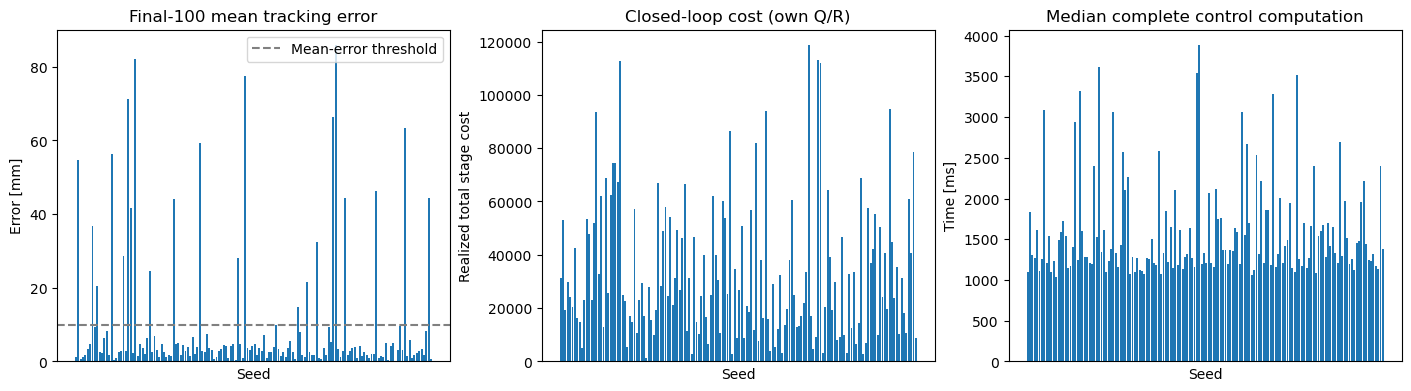

In [11]:
if rows:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
    axes[0].bar(df.seed.astype(str), 1000*df.mean_last_100)
    axes[0].set(title="Final-100 mean tracking error", ylabel="Error [mm]", xlabel="Seed")
    axes[0].axhline(10, color="grey", linestyle="--", label="Mean-error threshold")
    axes[0].legend()
    axes[1].bar(df.seed.astype(str), df.closed_loop_reference_cost)
    axes[1].set(title="Closed-loop cost (own Q/R)", ylabel="Realized total stage cost", xlabel="Seed", ylim=(0, None))
    axes[2].bar(df.seed.astype(str), df.median_control_compute_time_ms)
    axes[2].set(title="Median complete control computation", ylabel="Time [ms]", xlabel="Seed", ylim=(0, None))
    if len(rows) > 15:
        for ax in axes:
            ax.set_xticks([])
    plt.show()


## Inspect one completed rollout

The plot uses post-action fingertip errors and predictions aligned to that same output sample. The computation trace includes all five refinements. Change `PLOT_SEED` to inspect another completed seed.


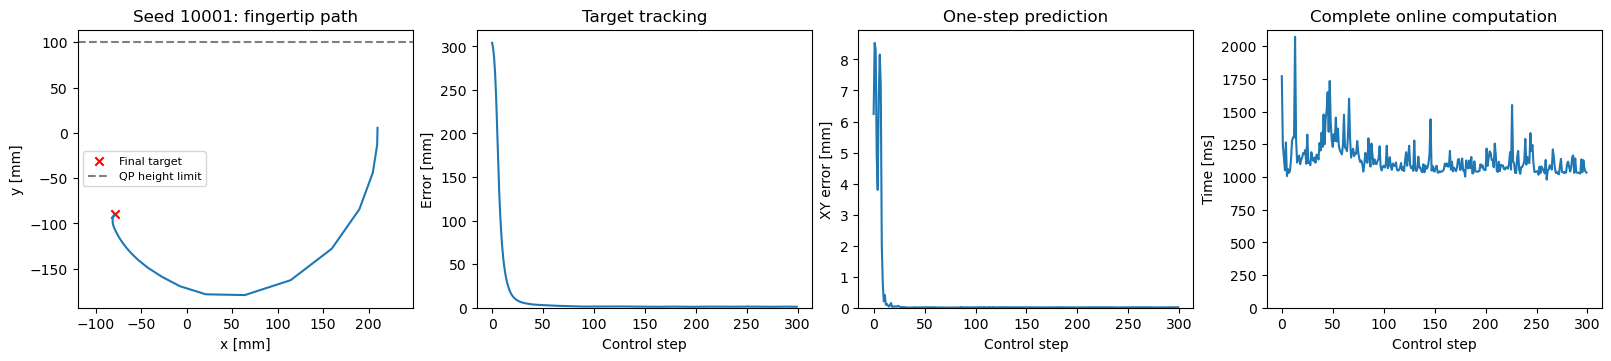

In [12]:
PLOT_SEED = SEED_START
path = RESULT_DIR / f"seed{PLOT_SEED}_control_results.npz"
if path.exists():
    with np.load(path) as trace:
        assert json.loads(trace['summary'].item())['steps'] == STEPS, 'Incompatible saved rollout'
        y, ref, target = trace["y"], trace["ref"], trace["target_xy"]
        distance = trace["distance"]
        prediction_error = trace["prediction_error_xy"]
        compute_ms = 1000*trace["control_compute_time_s"]
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), constrained_layout=True)
    axes[0].plot(1000*y[:, 6], 1000*y[:, 7])
    axes[0].scatter(*(1000*target), marker="x", c="red", label="Final target")
    axes[0].axhline(100, color="grey", linestyle="--", label="QP height limit")
    axes[0].set(title=f"Seed {PLOT_SEED}: fingertip path", xlabel="x [mm]", ylabel="y [mm]")
    axes[0].axis("equal")
    axes[0].legend(fontsize=8)
    axes[1].plot(1000*distance)
    axes[1].set(title="Target tracking", xlabel="Control step", ylabel="Error [mm]", ylim=(0, None))
    axes[2].plot(1000*prediction_error)
    axes[2].set(title="One-step prediction", xlabel="Control step", ylabel="XY error [mm]", ylim=(0, None))
    axes[3].plot(compute_ms)
    axes[3].set(title="Complete online computation", xlabel="Control step", ylabel="Time [ms]", ylim=(0, None))
    plt.show()
else:
    print(f"Seed {PLOT_SEED} has not completed.")
